# №9. Локальная бинаризация Ниблэка

Исследуем две фотографии текста с перепадом освещения. Сравниваем параметры
и размер окна, затем подбираем коэффициенты по двум фрагментам каждого кадра.
Все вычисления выполняются NumPy. Границы окна дополняются отражением.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    if figsize is None:
        figsize = (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

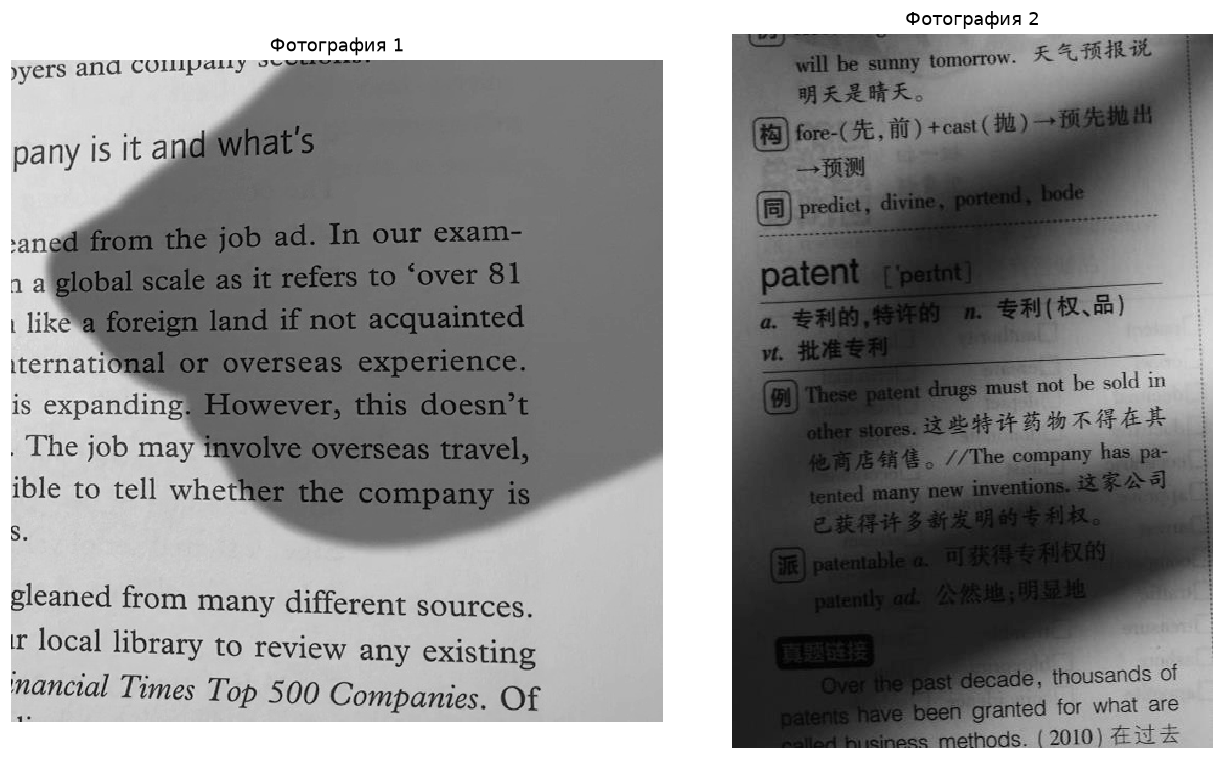

In [3]:
photos = [np.array(Image.open(f'data/text_photo_{i}.jpg').convert('L')) for i in (1, 2)]
show_images(photos, ['Фотография 1', 'Фотография 2'], cols=2, figsize=(12, 7))

## 1. Два коэффициента и размер окна

По лекции курса используем $T=\mu+\alpha\sigma+\beta$.
Здесь $\mu$ — среднее по окну $w\times w$, $\sigma$ — стандартное отклонение.
При $I\leq T$ пиксель становится чёрным. Коэффициент $\alpha$ управляет
вкладом локального контраста, $\beta$ сдвигает порог.

Средние считаются через интегральную сумму; дисперсия равна
$E[I^2]-E[I]^2$. Малые отрицательные значения от округления заменяются нулём.

In [4]:
def binarize(image, threshold):
    """Чёрный текст: I <= T. Белый фон: I > T."""
    return np.where(np.asarray(image) <= threshold, 0, 255).astype(np.uint8)


def otsu_threshold(image):
    """Максимум межклассовой дисперсии для 256 уровней яркости."""
    image = to_uint8(image)
    counts = np.bincount(image.ravel(), minlength=256).astype(float)
    probability = counts / counts.sum()
    weight = np.cumsum(probability)
    moment = np.cumsum(probability * np.arange(256))
    total_mean = moment[-1]
    denominator = weight * (1 - weight)
    score = np.zeros(256)
    valid = denominator > 1e-12
    score[valid] = (total_mean * weight[valid] - moment[valid]) ** 2 / denominator[valid]
    if np.any(valid):
        return int(np.argmax(score))
    # Однородное изображение содержит единственный класс.
    return int(image.flat[0])

In [5]:
def window_mean(image, w):
    """Среднее в квадратном окне через интегральное изображение."""
    radius = w // 2
    padded = np.pad(np.asarray(image, dtype=float), radius, mode='reflect')
    integral = np.pad(padded, ((1, 0), (1, 0))).cumsum(axis=0).cumsum(axis=1)
    sums = (integral[w:, w:] - integral[:-w, w:]
            - integral[w:, :-w] + integral[:-w, :-w])
    return sums / (w * w)


def local_stats(image, w):
    image = np.asarray(image, dtype=float)
    mean = window_mean(image, w)
    variance = np.maximum(window_mean(image * image, w) - mean * mean, 0)
    return mean, np.sqrt(variance)


def niblack(image, alpha=-0.2, beta=-5, w=31):
    mean, std = local_stats(image, w)
    threshold = mean + alpha * std + beta
    return binarize(image, threshold)


def niblack_extended(image, a=1, b=-0.2, c=-5, w=31):
    mean, std = local_stats(image, w)
    threshold = a * mean + b * std + c
    return binarize(image, threshold)

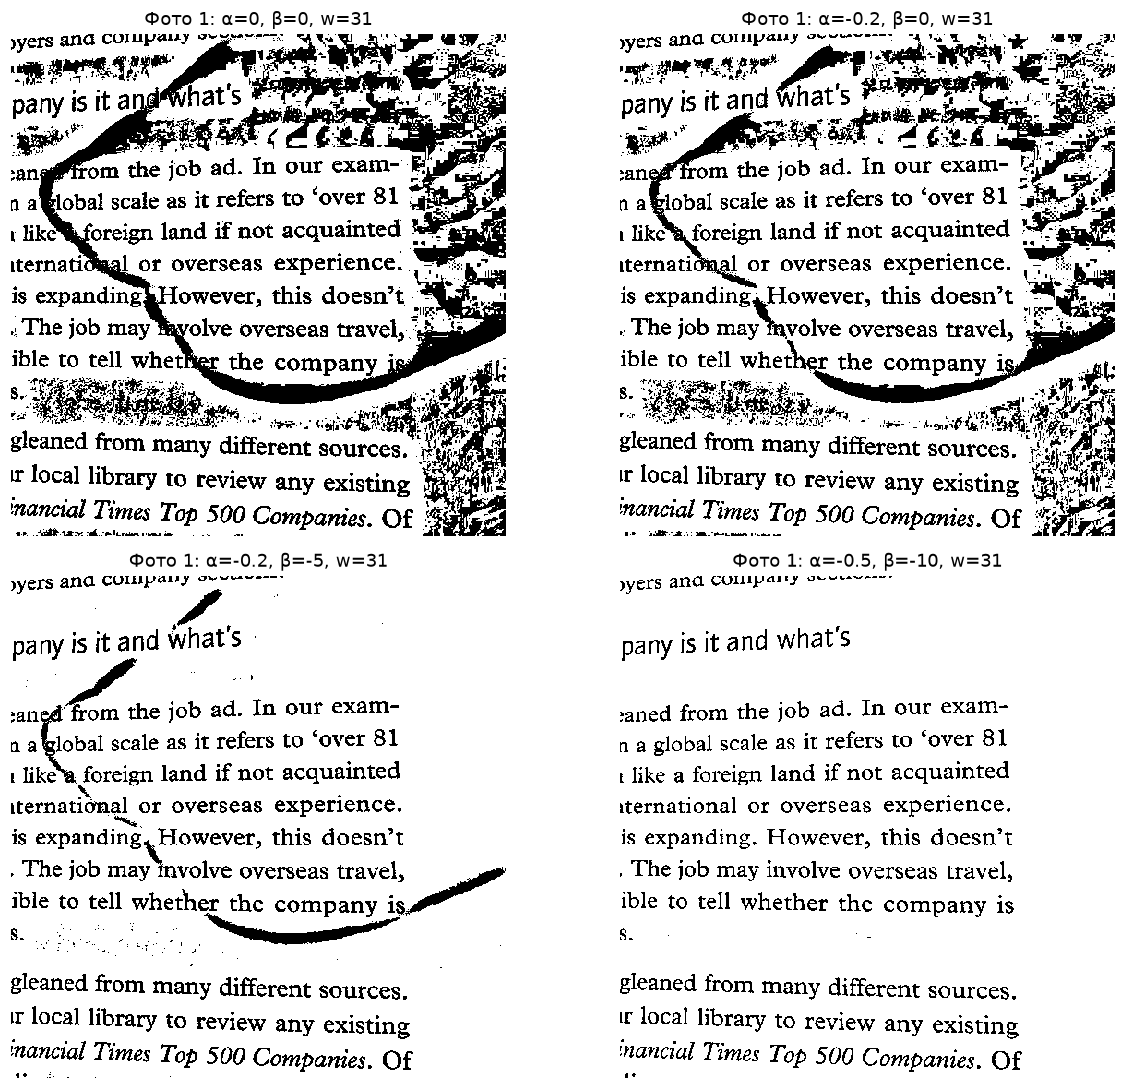

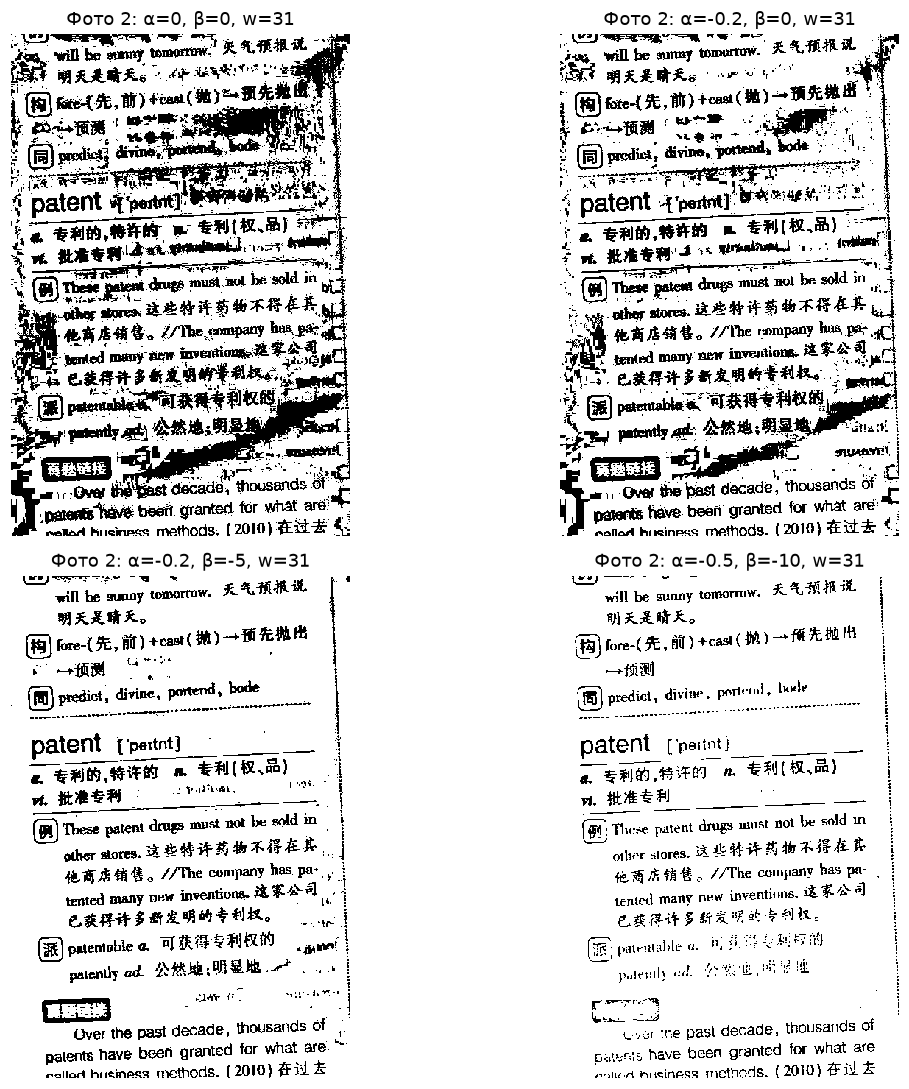

In [6]:
parameter_sets = [(0.0, 0), (-0.2, 0), (-0.2, -5), (-0.5, -10)]
for i, photo in enumerate(photos, 1):
    show_images([niblack(photo, alpha, beta, w=31) for alpha, beta in parameter_sets],
                [f'Фото {i}: α={alpha:g}, β={beta:g}, w=31' for alpha, beta in parameter_sets],
                cols=2, figsize=(12, 10))

В области бумаги с малым контрастом порог около среднего превращает часть
шума в чёрные точки. Сдвиг $\beta<0$ опускает порог и очищает фон.
Большой по модулю сдвиг уменьшает толщину светлых штрихов.

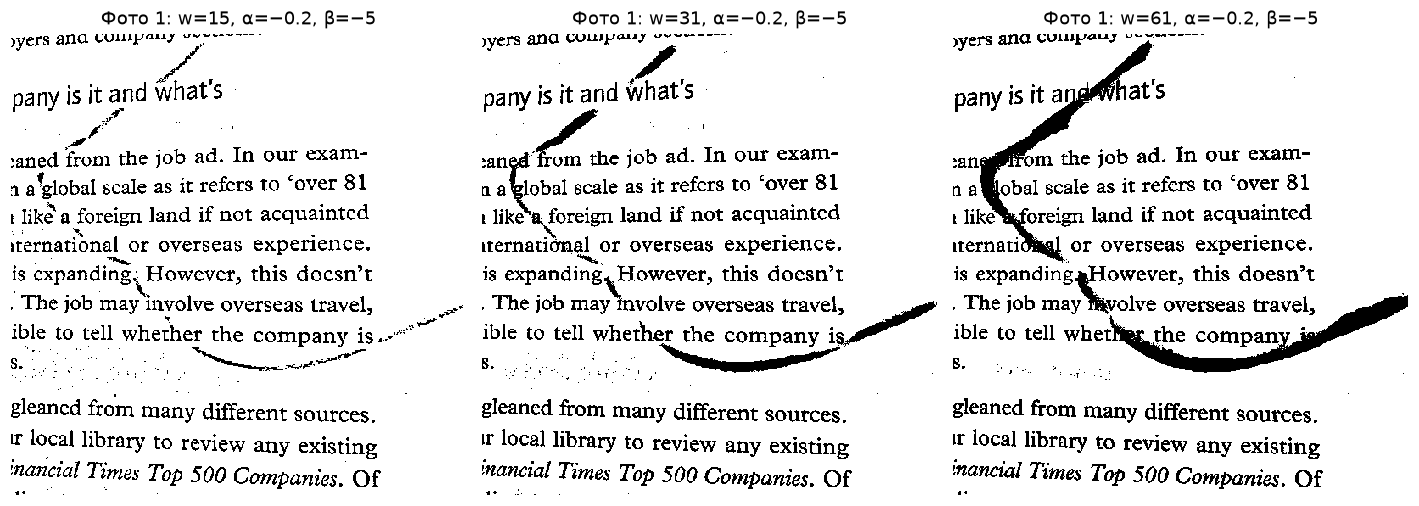

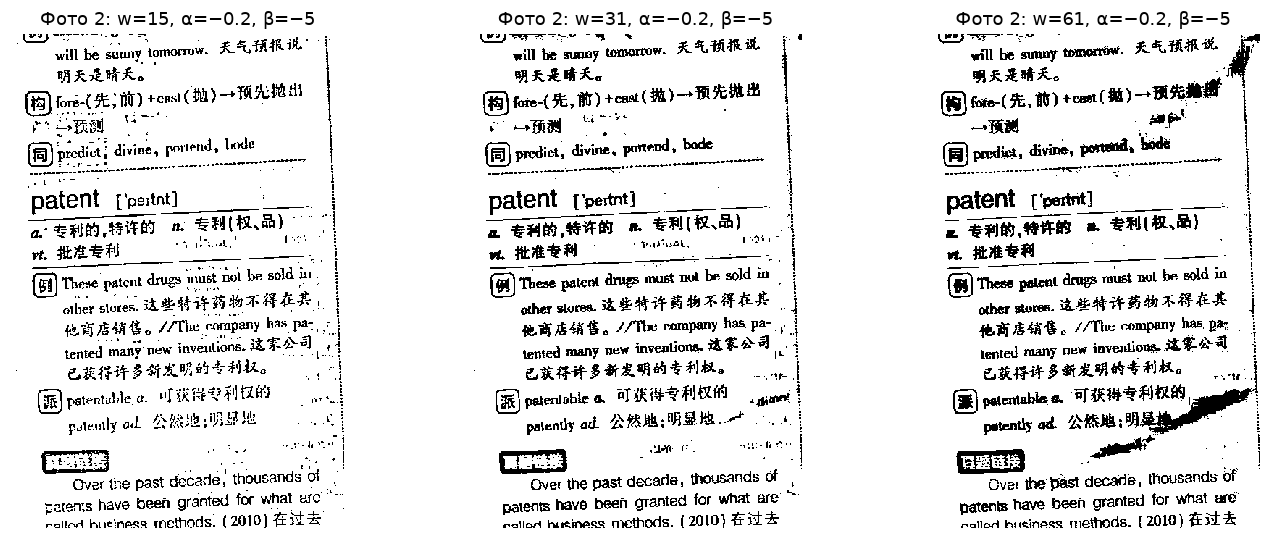

In [7]:
for i, photo in enumerate(photos, 1):
    windows = [15, 31, 61]
    show_images([niblack(photo, -0.2, -5, w) for w in windows],
                [f'Фото {i}: w={w}, α=−0.2, β=−5' for w in windows], cols=3,
                figsize=(13, 5))

## 2. Три коэффициента

Обобщим порог до $T=a\mu+b\sigma+c$. Коэффициент $a$ масштабирует локальное
среднее. При $a=1$, $b=\alpha$, $c=\beta$ получаем предыдущую формулу.
Это выбранное в работе линейное обобщение; двухпараметрический вариант
повторяет формулу лекции.

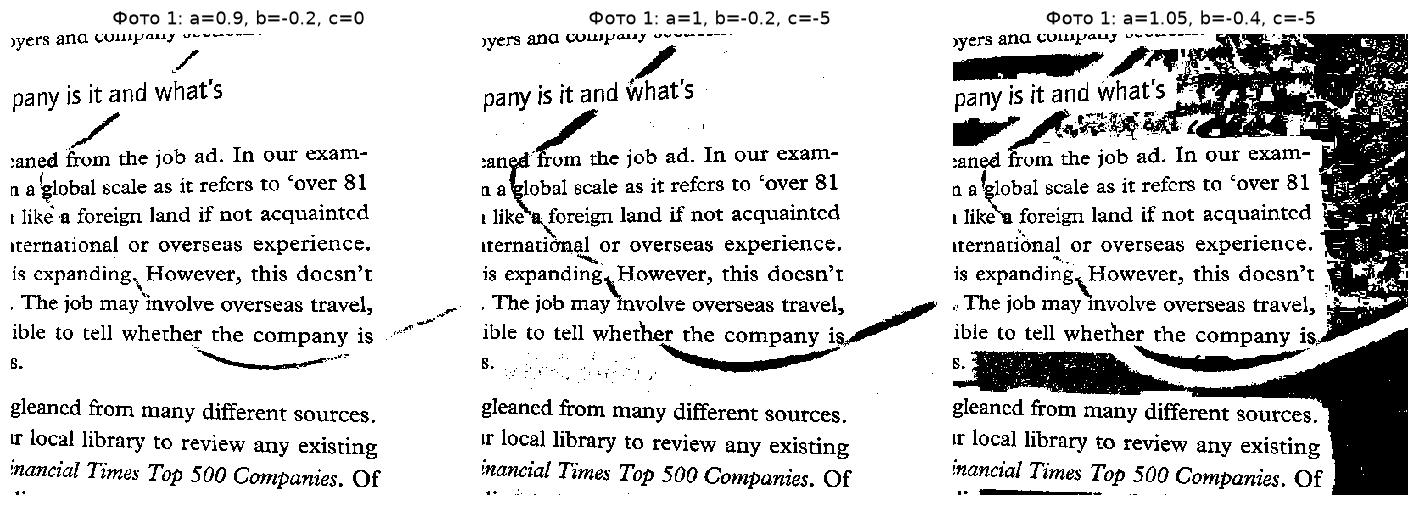

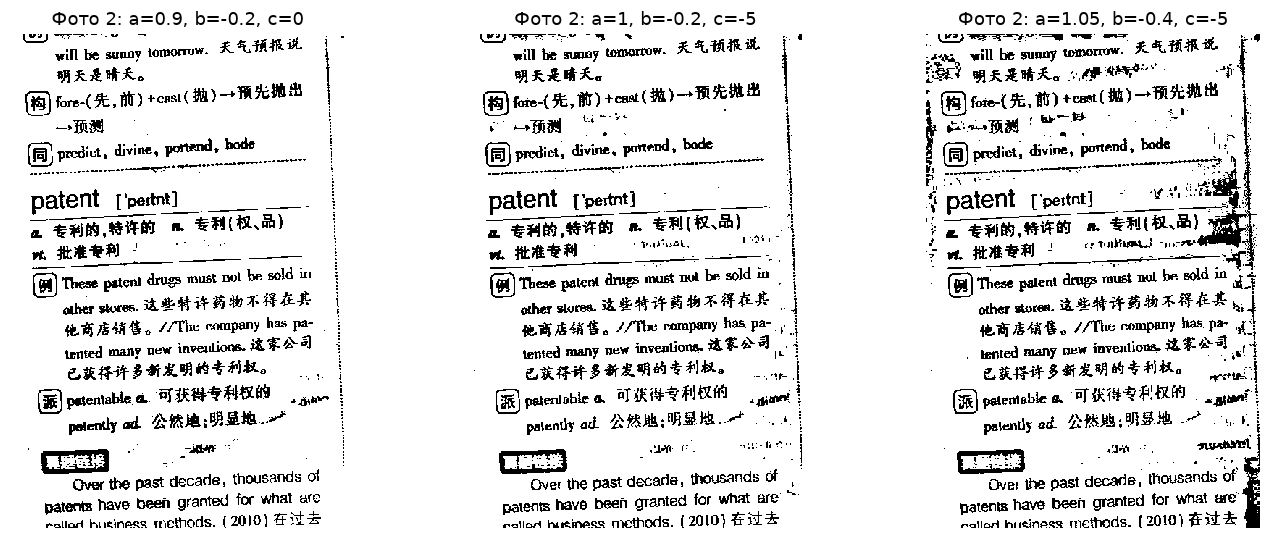

In [8]:
extended_sets = [(0.90, -0.2, 0), (1.00, -0.2, -5), (1.05, -0.4, -5)]
for i, photo in enumerate(photos, 1):
    show_images([niblack_extended(photo, a, b, c, w=31) for a, b, c in extended_sets],
                [f'Фото {i}: a={a:g}, b={b:g}, c={c:g}' for a, b, c in extended_sets],
                cols=3, figsize=(13, 5))

## 3. Эталонные счётчики на двух фрагментах

Выбираем текст в светлой и теневой части. Внутри каждого фрагмента освещение
меняется плавно; локальный Оцу задаёт опорную маску и число чёрных пикселей
$J_1$, $J_2$. Для Ниблэка статистики считаются на полном изображении: окно
у края фрагмента получает соседние пиксели исходного кадра.

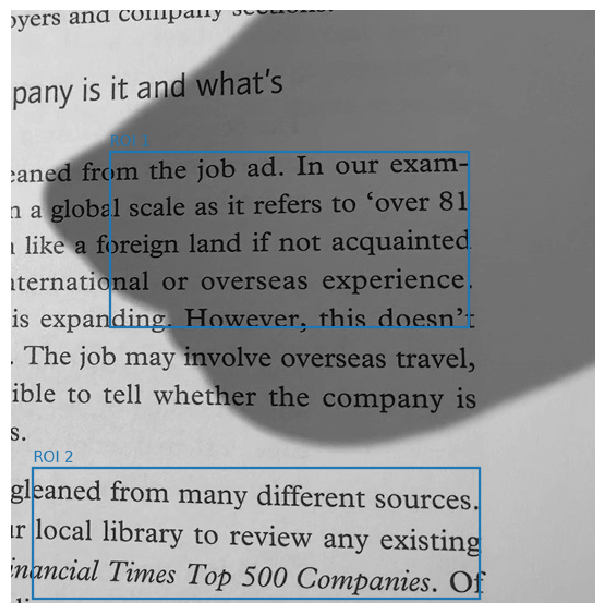

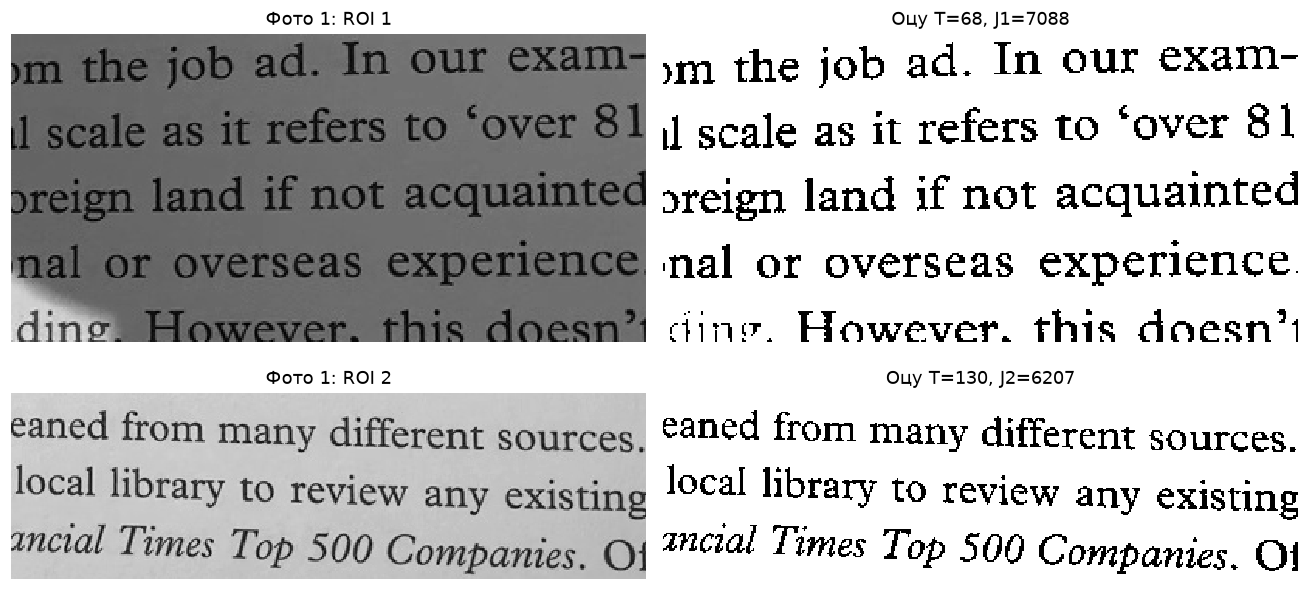

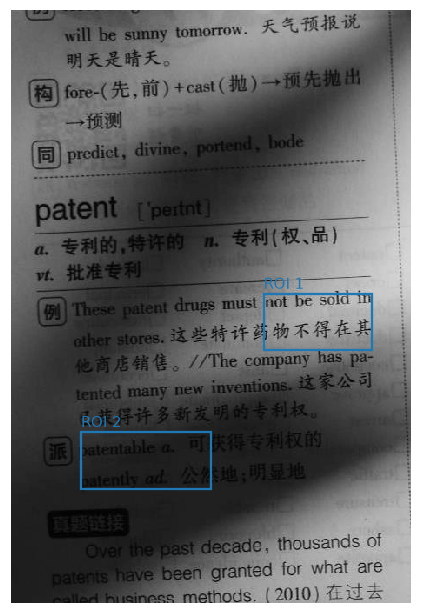

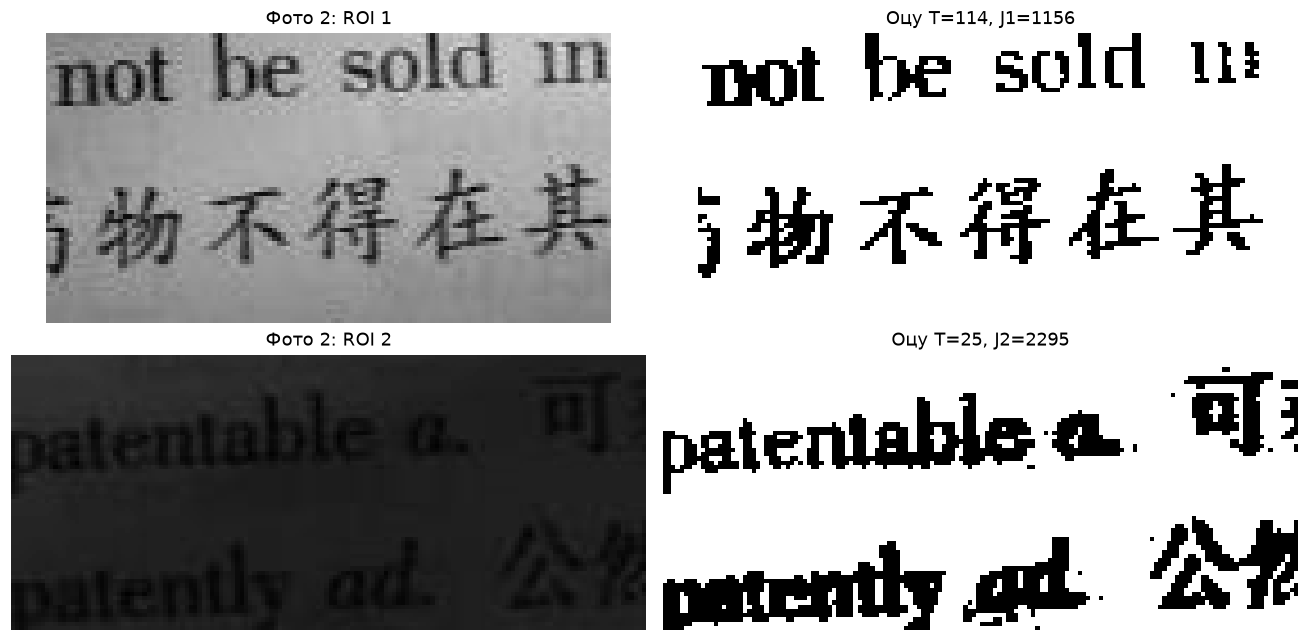

In [9]:
# Формат: (y0, y1, x0, x1). Области содержат текст и фон.
photo_rois = [
    [(130, 290, 90, 420), (420, 540, 20, 430)],
    [(326, 390, 290, 415), (485, 550, 80, 230)],
]

references_by_photo = []
for number, (photo, rois) in enumerate(zip(photos, photo_rois), 1):
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(photo, cmap='gray', vmin=0, vmax=255)
    crops = []
    references = []
    titles = []
    for i, (y0, y1, x0, x1) in enumerate(rois, 1):
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                  fill=False, edgecolor='tab:blue', lw=1.5))
        ax.text(x0, y0 - 6, f'ROI {i}', color='tab:blue')
        crop = photo[y0:y1, x0:x1]
        threshold = otsu_threshold(crop)
        reference = binarize(crop, threshold)
        crops.extend([crop, reference])
        titles.extend([f'Фото {number}: ROI {i}',
                       f'Оцу T={threshold}, J{i}={np.count_nonzero(reference == 0)}'])
        references.append(reference)
    ax.axis('off')
    plt.show()
    show_images(crops, titles, cols=2, figsize=(12, 6))
    references_by_photo.append(references)

## 4. Расширенный перебор a и b

Минимизируем $L(a,b)=|J_1-B_1(a,b)|+|J_2-B_2(a,b)|$ при $w=31$.
Здесь $B_i$ — число чёрных пикселей Ниблэка в i-м фрагменте.
Для первого кадра фиксируем $c=-5$, для тёмного второго — $c=0$:
сдвиг 5 составляет 20% локального порога Оцу 25 в теневой области.
Сравнение до и после подбора использует одинаковое $c$.

Сначала обследуем $a\in[0,1.5]$, $b\in[-2,8]$, затем дважды уменьшаем шаг
вокруг лучшей пары. При равенстве ошибок выбираем пару ближе к $(1,-0.2)$.
Нулевая ошибка достигает абсолютного минимума счётчиков. Положительный минимум
характеризует обследованные диапазоны и шаги.

Для быстрого перебора используем эквивалентное условие
$a\geq(I-b\sigma-c)/\mu$ при $\mu>0$. Сортировка этих границ и `searchsorted`
дают число чёрных пикселей сразу для всех значений $a$. Статистики окна
по-прежнему рассчитаны на полном кадре.

Фото 1: c=-5, w=31
Широкая сетка    a=1.010000  b=-0.800000  L=34
Уточнение        a=1.017500  b=-0.836000  L=1
Уточнение        a=1.017050  b=-0.834320  L=0


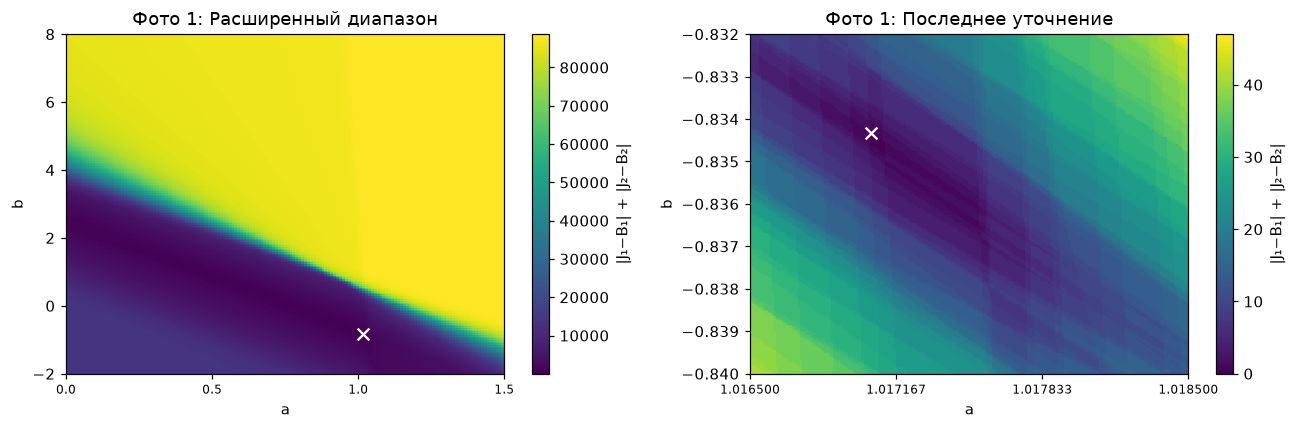

Фото 2: c=0, w=31
Широкая сетка    a=0.010000  b=3.300000  L=19
Уточнение        a=0.010000  b=3.304000  L=14
Уточнение        a=0.011000  b=3.300720  L=14


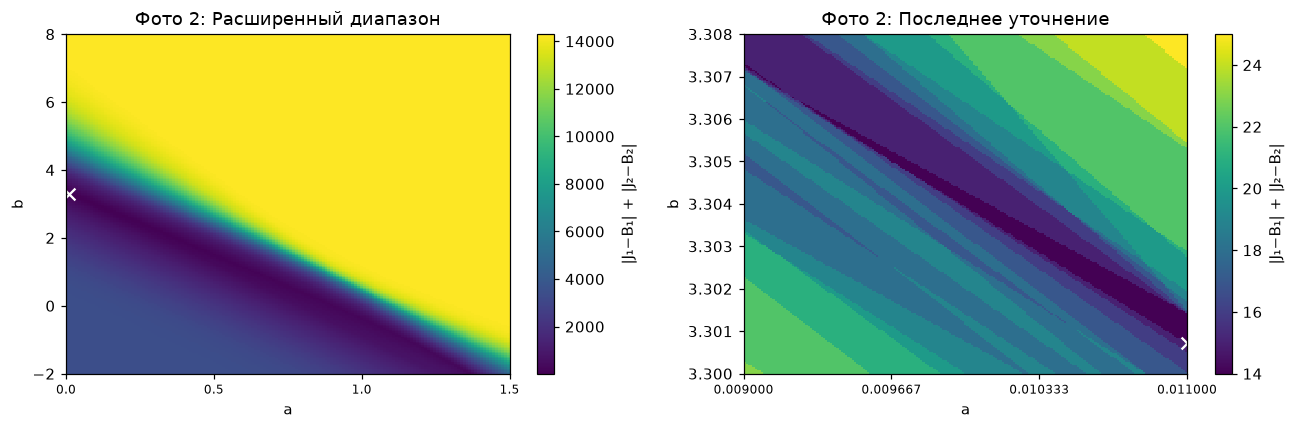

In [10]:
def fit_parameters(image, rois, references, a_values, b_values, w=31, c=-5):
    mean, std = local_stats(image, w)
    parts = []
    for (y0, y1, x0, x1), reference in zip(rois, references):
        sl = np.s_[y0:y1, x0:x1]
        parts.append((image[sl].ravel(), mean[sl].ravel(), std[sl].ravel(),
                      np.count_nonzero(reference == 0)))

    loss = np.zeros((len(b_values), len(a_values)), dtype=int)
    for ib, b in enumerate(b_values):
        for pixels, mu, sigma, target in parts:
            positive = mu > 0
            limits = (pixels[positive] - b * sigma[positive] - c) / mu[positive]
            counts = np.searchsorted(np.sort(limits), a_values, side='right')
            # При нулевом среднем условие определяется слагаемыми b*sigma+c.
            counts += np.count_nonzero(pixels[~positive] <= b * sigma[~positive] + c)
            loss[ib] += np.abs(counts - target)

    candidates = np.argwhere(loss == loss.min())
    distances = [(a_values[ia] - 1) ** 2 + (b_values[ib] + 0.2) ** 2
                 for ib, ia in candidates]
    ib, ia = candidates[np.argmin(distances)]
    best = (float(a_values[ia]), float(b_values[ib]), int(loss[ib, ia]))
    return best, loss


def refine_parameters(image, rois, references, c):
    a_coarse = np.round(np.arange(0, 1.501, 0.01), 5)
    b_coarse = np.round(np.arange(-2, 8.001, 0.05), 5)
    best, coarse_loss = fit_parameters(image, rois, references, a_coarse, b_coarse, c=c)
    history = [('Широкая сетка', *best)]

    # Два уточнения: окрестность, шаг по a, окрестность, шаг по b.
    for radius_a, step_a, radius_b, step_b in [(0.03, 0.0005, 0.15, 0.002),
                                              (0.001, 0.00001, 0.004, 0.00004)]:
        a_fine = np.round(np.arange(max(0, best[0] - radius_a),
                                    min(1.5, best[0] + radius_a) + step_a / 2, step_a), 6)
        b_fine = np.round(np.arange(max(-2, best[1] - radius_b),
                                    min(8, best[1] + radius_b) + step_b / 2, step_b), 6)
        previous = best
        candidate, fine_loss = fit_parameters(image, rois, references, a_fine, b_fine, c=c)
        if candidate[2] <= previous[2]:
            best = candidate
        history.append(('Уточнение', *best))
    return best, history, (a_coarse, b_coarse, coarse_loss), (a_fine, b_fine, fine_loss)


selected_c = [-5, 0]
fitted = []
for number, (photo, rois, references, c) in enumerate(
        zip(photos, photo_rois, references_by_photo, selected_c), 1):
    best, history, coarse, fine = refine_parameters(photo, rois, references, c)
    fitted.append(best)
    print(f'Фото {number}: c={c}, w=31')
    for label, a, b, error in history:
        print(f'{label:15s}  a={a:.6f}  b={b:.6f}  L={error}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (a_grid, b_grid, loss), title in zip(
            axes, [coarse, fine], ['Расширенный диапазон', 'Последнее уточнение']):
        mesh = ax.imshow(loss, origin='lower', aspect='auto', cmap='viridis',
                         extent=[a_grid[0], a_grid[-1], b_grid[0], b_grid[-1]])
        ax.scatter(best[0], best[1], marker='x', color='white', s=60)
        ax.set(xlabel='a', ylabel='b', title=f'Фото {number}: {title}')
        ax.set_xticks(np.linspace(a_grid[0], a_grid[-1], 4))
        ax.tick_params(axis='x', labelsize=8)
        fig.colorbar(mesh, ax=ax, label='|J₁−B₁| + |J₂−B₂|')
    plt.tight_layout()
    plt.show()

Фото 1: число чёрных пикселей
ROI   Локальный Оцу J   Глобальный Оцу   Ниблэк до   Ниблэк после   Ошибок маски после
 1          7088             51933          8579          7088               432
 2          6207              7106          7467          6207               304
L до=2751, L после=0



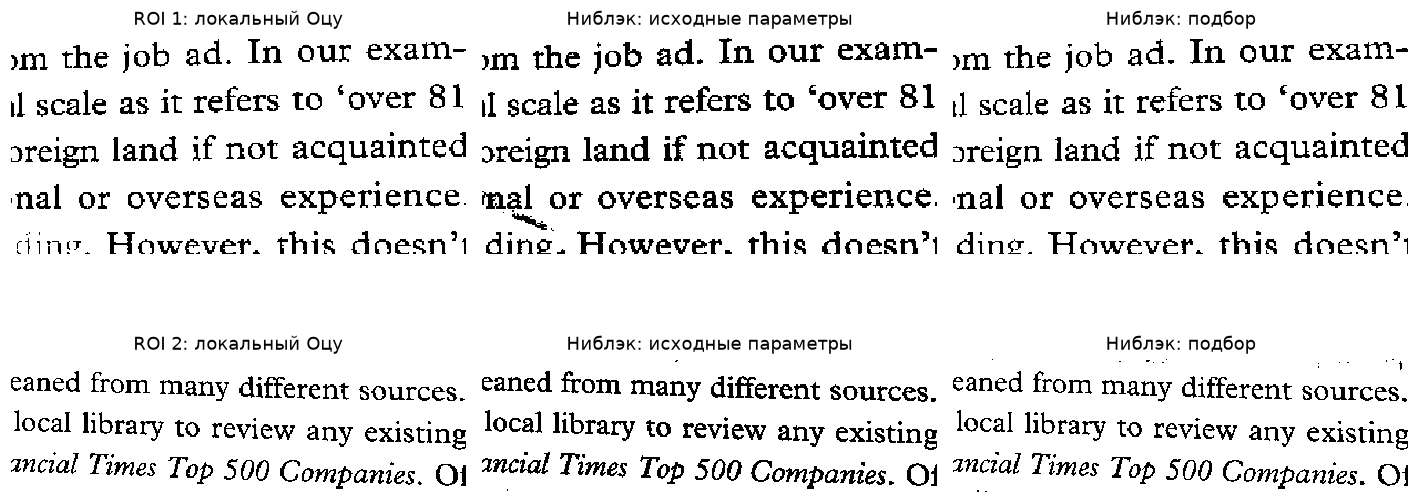

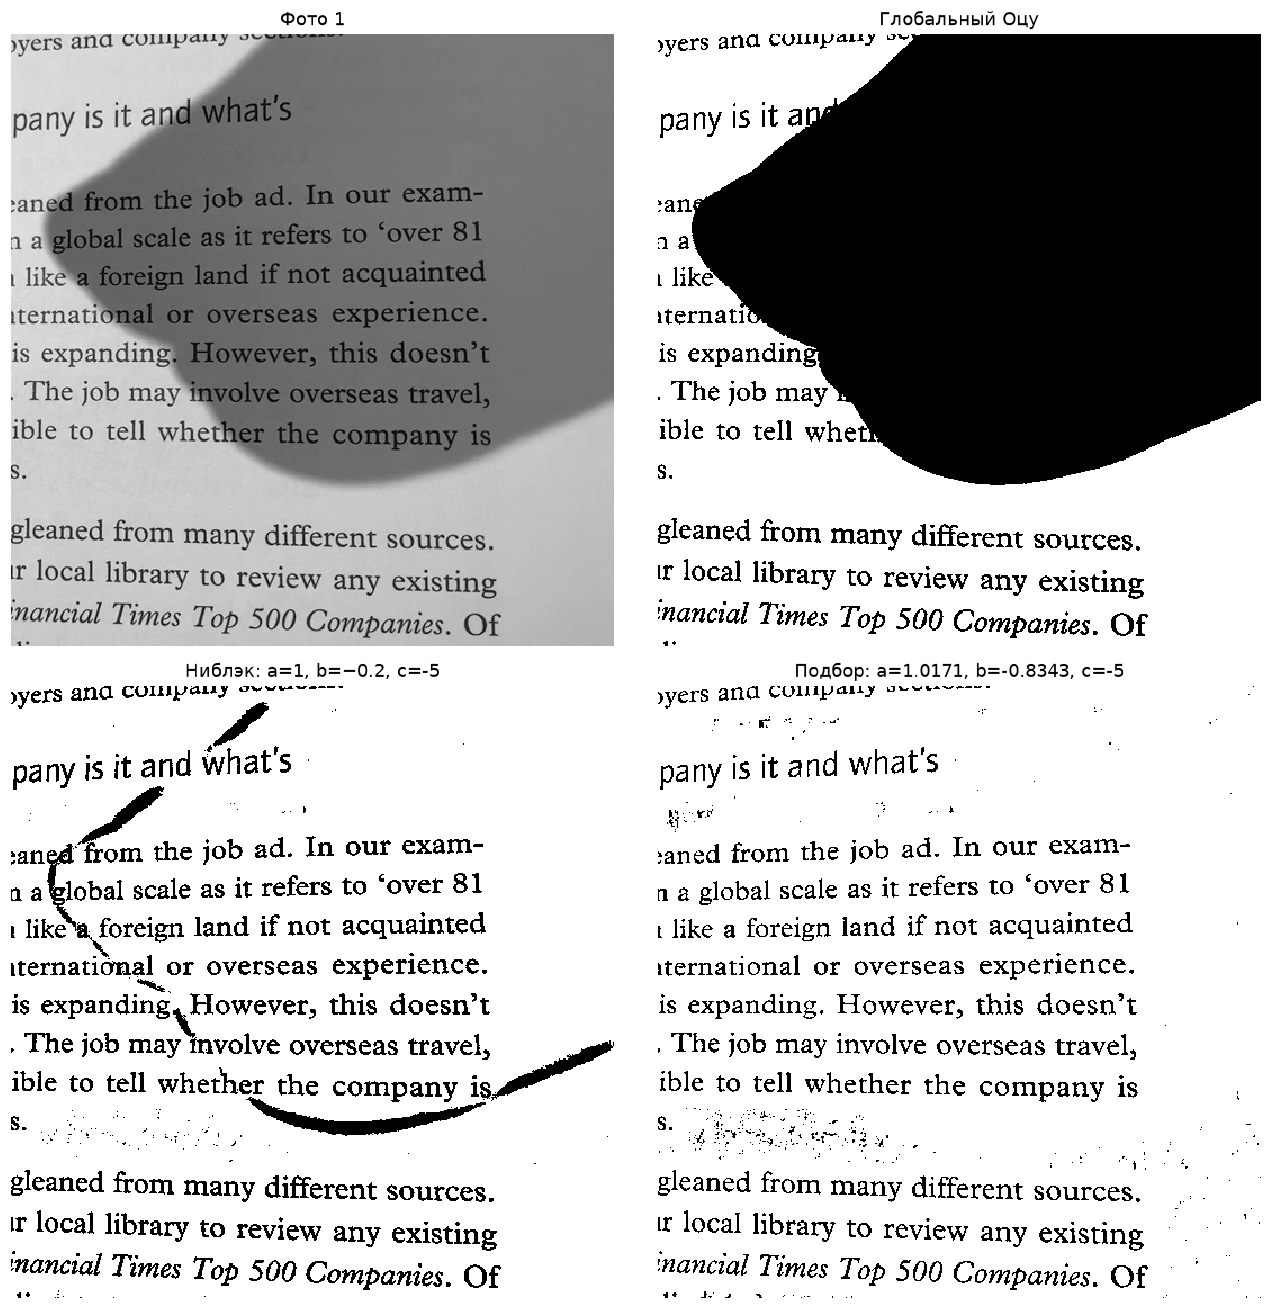

Фото 2: число чёрных пикселей
ROI   Локальный Оцу J   Глобальный Оцу   Ниблэк до   Ниблэк после   Ошибок маски после
 1          1156               830          1499          1170               104
 2          2295              9750          2626          2295               618
L до=674, L после=14



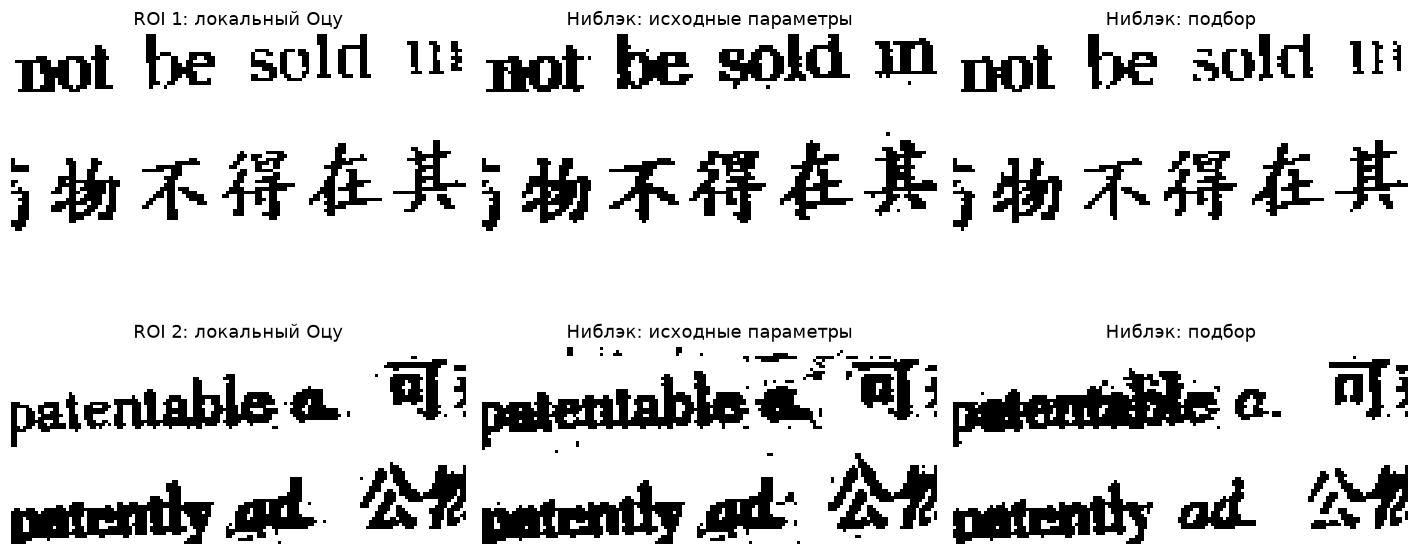

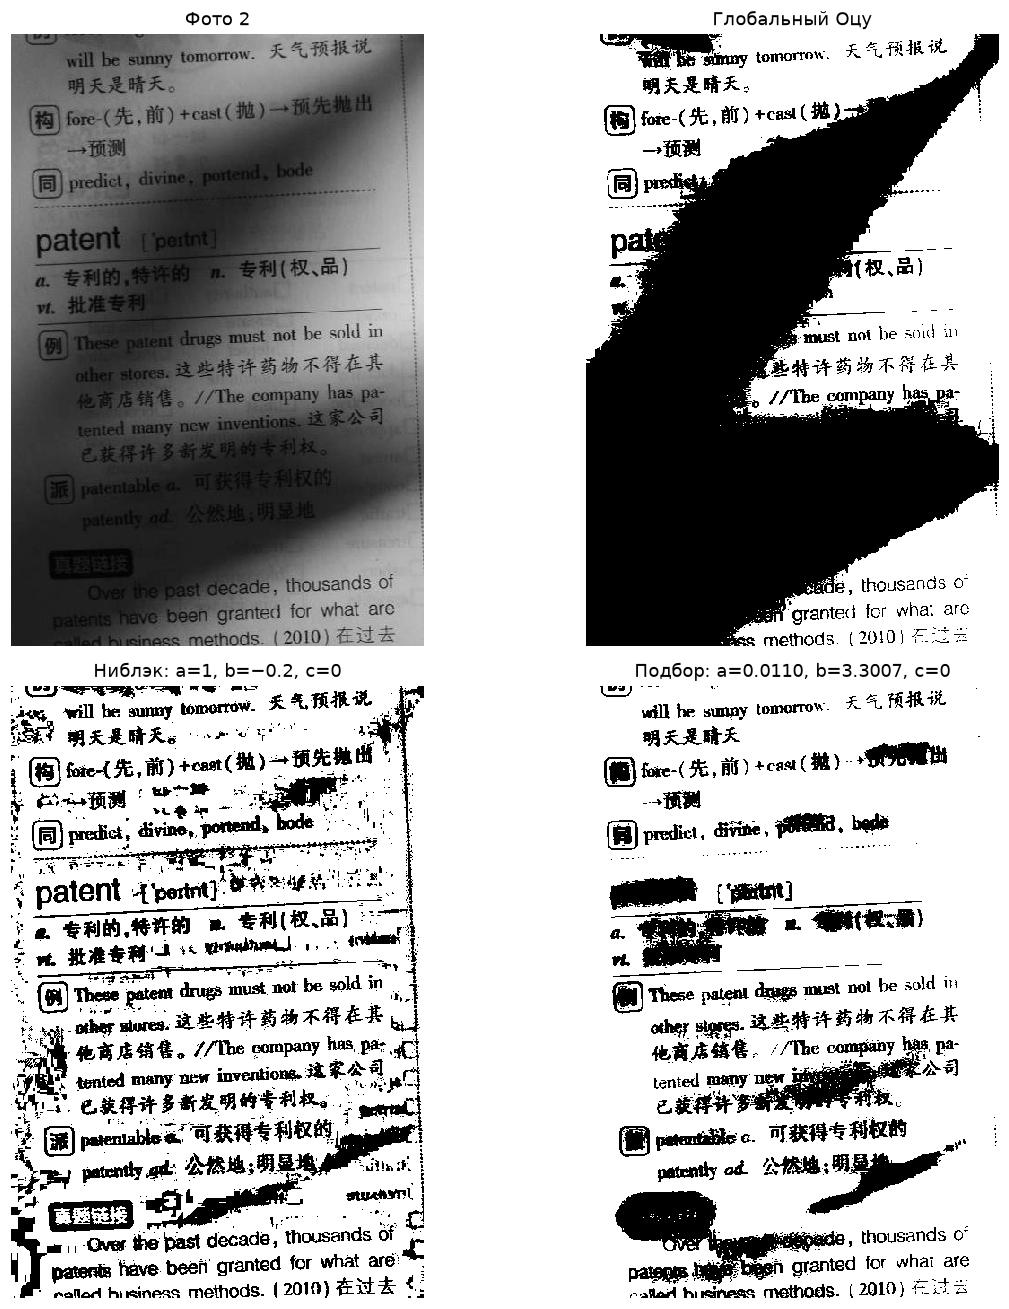

In [11]:
final_masks = []
for number, (photo, rois, references, best, c) in enumerate(
        zip(photos, photo_rois, references_by_photo, fitted, selected_c), 1):
    global_mask = binarize(photo, otsu_threshold(photo))
    before = niblack_extended(photo, 1, -0.2, c, w=31)
    after = niblack_extended(photo, best[0], best[1], c, w=31)
    final_masks.append(after)
    print(f'Фото {number}: число чёрных пикселей')
    print('ROI   Локальный Оцу J   Глобальный Оцу   Ниблэк до   Ниблэк после   Ошибок маски после')
    before_loss = 0
    after_loss = 0
    comparison = []
    titles = []
    for i, ((y0, y1, x0, x1), reference) in enumerate(zip(rois, references), 1):
        sl = np.s_[y0:y1, x0:x1]
        target = np.count_nonzero(reference == 0)
        counts = [np.count_nonzero(mask[sl] == 0) for mask in (global_mask, before, after)]
        mismatches = np.count_nonzero(after[sl] != reference)
        before_loss += abs(target - counts[1])
        after_loss += abs(target - counts[2])
        print(f'{i:2d}      {target:8d}          {counts[0]:8d}      {counts[1]:8d}      '
              f'{counts[2]:8d}          {mismatches:8d}')
        comparison.extend([reference, before[sl], after[sl]])
        titles.extend([f'ROI {i}: локальный Оцу', 'Ниблэк: исходные параметры', 'Ниблэк: подбор'])
    print(f'L до={before_loss}, L после={after_loss}\n')
    show_images(comparison, titles, cols=3, figsize=(13, 6))
    show_images([photo, global_mask, before, after],
                [f'Фото {number}', 'Глобальный Оцу', f'Ниблэк: a=1, b=−0.2, c={c}',
                 f'Подбор: a={best[0]:.4f}, b={best[1]:.4f}, c={c}'],
                cols=2, figsize=(12, 12))

## 5. Контроль фона

Дополнительно отмечаем пустую бумагу. Доля чёрных пикселей в этих областях
измеряет мусор фона. Подбор по двум текстовым областям контролирует сумму
пикселей букв; чистота отдельной области бумаги проверяется самостоятельно.

Фото 1, мусор фона: базовый 47.77%, с β=−5 0.00%, после подбора 0.02%.


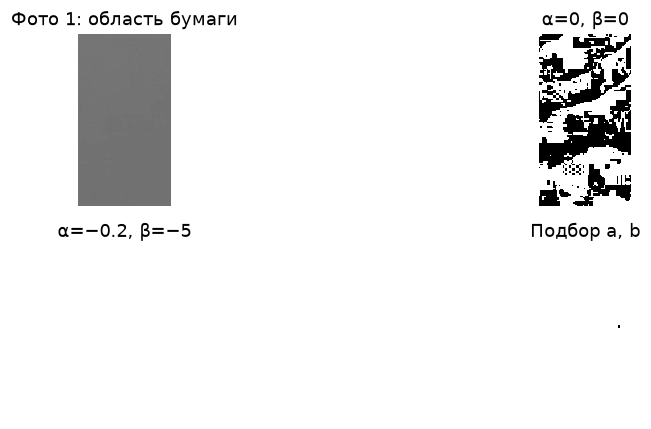

Фото 2, мусор фона: базовый 22.95%, с β=−5 0.00%, после подбора 0.00%.


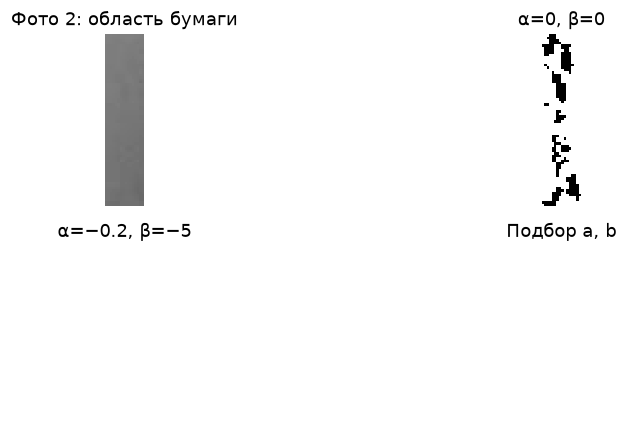

In [12]:
# Пустая бумага: (y0, y1, x0, x1).
background_rois = [(150, 280, 455, 525), (220, 290, 2, 18)]
for i, (photo, final_mask, bounds) in enumerate(zip(photos, final_masks, background_rois), 1):
    y0, y1, x0, x1 = bounds
    sl = np.s_[y0:y1, x0:x1]
    raw = niblack(photo, alpha=0, beta=0, w=31)
    shifted = niblack(photo, alpha=-0.2, beta=-5, w=31)
    masks = [raw[sl], shifted[sl], final_mask[sl]]
    ratios = [100 * np.mean(mask == 0) for mask in masks]
    print(f'Фото {i}, мусор фона: базовый {ratios[0]:.2f}%, '
          f'с β=−5 {ratios[1]:.2f}%, после подбора {ratios[2]:.2f}%.')
    show_images([photo[sl], *masks],
                [f'Фото {i}: область бумаги', 'α=0, β=0', 'α=−0.2, β=−5', 'Подбор a, b'],
                cols=2, figsize=(12, 4))

## Вывод

Локальный порог учитывает изменение освещения по кадру. Размер окна задаёт
масштаб оценки фона, а коэффициенты управляют толщиной штрихов и количеством
чёрных точек на бумаге. Расширенный перебор и два уточнения дают минимум внутри
исследованного диапазона. Таблицы показывают число пикселей в каждой области.

У второго кадра выбранный критерий приводит к малому коэффициенту при среднем
и большому весу стандартного отклонения. Маска получает дополнительные пятна
вне опорных фрагментов. Счётчики контролируют число чёрных точек; одинаковое число
допускает разное расположение пикселей. Поэтому рядом приведены полные изображения,
маски фрагментов, их попиксельное отличие и контроль пустой бумаги.
Опорная разметка Оцу служит приближённым эталоном для выбранных областей.

Формула и схема подбора: лекция курса
[«Яркостная обработка и бинаризация»](../06_Яркостная_обработка_и_бинаризация_изображений.pdf),
слайды 24–29. Трёхпараметрическая формула явно задана в этой работе.